In [1]:
from sklearn.datasets import fetch_california_housing
import pandas as pd

# Tải và chuyển đổi dữ liệu thành dạng bảng Pandas DataFrame
housing = fetch_california_housing(as_frame=True)
df = housing.frame

# Kiểm tra 5 dòng đầu tiên của dữ liệu
print(df.head())

   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  MedHouseVal  
0    -122.23        4.526  
1    -122.22        3.585  
2    -122.24        3.521  
3    -122.25        3.413  
4    -122.25        3.422  


In [ ]:
from sklearn.datasets import fetch_california_housing

# chậy khii cần tải dữ liệu về
housing = fetch_california_housing(as_frame=True)
df = housing.frame

# Lưu thành file california_housing.csv
df.to_csv('california_housing.csv', index=False)
print("Đã lưu thành công file california_housing.csv!")

In [2]:
print("Shape:", df.shape)
df.info()

Shape: (20640, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [3]:
print("\n=== khong co du lieu ===")
print(df.isnull().sum())


=== khong co du lieu ===
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64


In [4]:
# Tách biến đặc trưng (X) và biến mục tiêu (y)
X = df.drop(columns=['MedHouseVal'])  # 8 cột đặc trưng đầu vào
y = df['MedHouseVal']                 # Cột giá nhà mục tiêu

In [5]:
from sklearn.model_selection import train_test_split

In [6]:
#Chia tập dữ liệu thành Train (80%) và Test (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [7]:
from sklearn.preprocessing import StandardScaler

In [8]:
#Chuẩn hóa dữ liệu (Cực kỳ quan trọng cho thuật toán KNN)
scaler = StandardScaler()

#fit_transform trên tập train để tính toán trung bình (mean) và độ lệch chuẩn (std), sau đó chuẩn hóa
X_train_scaled = scaler.fit_transform(X_train)

#transform trên tập test (chỉ dùng mean và std đã học từ tập train để tránh rò rỉ dữ liệu - Data Leakage)
X_test_scaled = scaler.transform(X_test)

print("\n--- HOÀN TẤT TIỀN XỬ LÝ ---")
print(f"Kích thước tập Train sau chuẩn hóa: {X_train_scaled.shape}")
print(f"Kích thước tập Test sau chuẩn hóa: {X_test_scaled.shape}")


--- HOÀN TẤT TIỀN XỬ LÝ ---
Kích thước tập Train sau chuẩn hóa: (16512, 8)
Kích thước tập Test sau chuẩn hóa: (4128, 8)


In [9]:

# Ghép lại X_train và y_train thành một DataFrame để lưu chung cho dễ
train_df = pd.DataFrame(X_train, columns=X.columns)
train_df['MedHouseVal'] = y_train.values

# Lưu tập Train
train_df.to_csv('train_data.csv', index=False)

# Tương tự cho tập Test (nếu cần)
test_df = pd.DataFrame(X_test, columns=X.columns)
test_df['MedHouseVal'] = y_test.values
test_df.to_csv('test_data.csv', index=False)

print("Đã lưu thành công train_data.csv và test_data.csv!")

Đã lưu thành công train_data.csv và test_data.csv!


thử nghiệm với code KNN(thử)

In [11]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# 1. Khởi tạo mô hình KNN Regressor với K=5 láng giềng gần nhất
knn_model = KNeighborsRegressor(n_neighbors=5)

# 2. Huấn luyện mô hình (Dữ liệu đầu vào yêu cầu: X_train_scaled dạng 2D array, y_train dạng 1D array)
knn_model.fit(X_train_scaled, y_train)

# 3. Dự đoán trên tập kiểm tra (Dữ liệu đầu vào: X_test_scaled phải có cùng số cột và định dạng chuẩn hóa như X_train_scaled)
y_pred = knn_model.predict(X_test_scaled)

# 4. Đánh giá kết quả
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("--- KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH ---")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"R-squared (R2 Score): {r2:.4f}")

--- KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH ---
Root Mean Squared Error (RMSE): 0.6576
R-squared (R2 Score): 0.6700


### Các công thức tính khoảng cách tích hợp sẵn trong KNN (`scikit-learn`)

Khi khởi tạo `KNeighborsRegressor(metric='tên_khoảng_cách')`, bạn có thể lựa chọn các cấu hình sau:

| Tên tham số `metric` | Tên khoảng cách | Công thức toán học | Mô tả ngắn gọn |
| :--- | :--- | :--- | :--- |
| **`'minkowski'`** (Mặc định) | Minkowski Distance | $D(x, y) = \left( \sum |x_i - y_i|^p \right)^{1/p}$ | Công thức tổng quát. Với `p=2` là Euclidean, `p=1` là Manhattan. |
| **`'euclidean'`** | Euclidean Distance | $D(x, y) = \sqrt{\sum (x_i - y_i)^2}$ | Đo độ dài đường thẳng nối liền 2 điểm. |
| **`'manhattan'`** | Manhattan Distance | $D(x, y) = \sum |x_i - y_i|$ | Đo khoảng cách theo các đường vuông góc (giá trị tuyệt đối). |
| **`'chebyshev'`** | Chebyshev Distance | $D(x, y) = \max(|x_i - y_i|)$ | Lấy khoảng cách lớn nhất trong số các chiều đơn lẻ. |

In [12]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# Định nghĩa danh sách các khoảng cách muốn thử nghiệm
metrics = {
    'Euclidean': {'metric': 'euclidean'},
    'Manhattan': {'metric': 'manhattan'},
    'Chebyshev': {'metric': 'chebyshev'},
    'Minkowski (p=3)': {'metric': 'minkowski', 'p': 3}
}

best_metric_name = None
best_rmse = float('inf')
best_r2 = -float('inf')
results = {}

print("--- ĐANG THỬ NGHIỆM CÁC CÔNG THỨC KHOẢNG CÁCH ---\n")

for name, params in metrics.items():
    # Khởi tạo mô hình với các tham số tương ứng
    knn = KNeighborsRegressor(n_neighbors=5, **params)

    # Huấn luyện mô hình
    knn.fit(X_train_scaled, y_train)

    # Dự đoán
    y_pred = knn.predict(X_test_scaled)

    # Tính toán chỉ số đánh giá
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    results[name] = {'RMSE': rmse, 'R2': r2}
    print(f"{name:18} -> RMSE: {rmse:.4f} | R2 Score: {r2:.4f}")

    # Lưu lại khoảng cách tốt nhất dựa trên RMSE thấp nhất
    if rmse < best_rmse:
        best_rmse = rmse
        best_r2 = r2
        best_metric_name = name

print("\n" + "="*45)
print(f"=> KẾT LUẬN: Khoảng cách tối ưu nhất là: {best_metric_name}")
print(f"   - RMSE thấp nhất: {best_rmse:.4f}")
print(f"   - R2 Score cao nhất: {best_r2:.4f}")
print("="*45)

--- ĐANG THỬ NGHIỆM CÁC CÔNG THỨC KHOẢNG CÁCH ---

Euclidean          -> RMSE: 0.6576 | R2 Score: 0.6700
Manhattan          -> RMSE: 0.6236 | R2 Score: 0.7032
Chebyshev          -> RMSE: 0.6962 | R2 Score: 0.6302
Minkowski (p=3)    -> RMSE: 0.6772 | R2 Score: 0.6501

=> KẾT LUẬN: Khoảng cách tối ưu nhất là: Manhattan
   - RMSE thấp nhất: 0.6236
   - R2 Score cao nhất: 0.7032


In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [16]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error
import numpy as np

# 1. Tạo một Pipeline bao gồm chuẩn hóa dữ liệu và mô hình KNN
knn_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsRegressor())
])

# 2. Định nghĩa không gian tham số đã tối ưu hóa để chạy nhanh hơn
# Tập trung vào các thuật toán triển vọng nhất (Manhattan, Euclidean) và chỉ thử các số K lẻ
param_grid = {
    'knn__n_neighbors': [3, 5, 7, 9, 11, 13, 15, 17],
    'knn__metric': ['euclidean', 'manhattan', 'minkowski'],
    'knn__p': [1, 2] # p=1 tương đương Manhattan, p=2 tương đương Euclidean
}

# 3. Khởi tạo GridSearchCV với K-Fold Cross Validation (cv=5)
grid_search = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=param_grid,
    scoring='neg_mean_squared_error',
    cv=5,
    n_jobs=-1, # Sử dụng tất cả các nhân CPU để song song hóa
    verbose=1
)

# 4. Tiến hành tìm kiếm trên tập huấn luyện (X_train, y_train)
print("--- BẮT ĐẦU GRID SEARCH (ĐÃ TỐI ƯU TỐC ĐỘ) ---")
grid_search.fit(X_train, y_train)

# 5. Lấy ra kết quả tốt nhất
best_params = grid_search.best_params_
best_score = np.sqrt(-grid_search.best_score_)

print("\n" + "="*50)
print("KẾT QUẢ TỐI ƯU NHẤT TỪ GRID SEARCH:")
print(f"  - K tốt nhất (n_neighbors): {best_params['knn__n_neighbors']}")
print(f"  - Công thức khoảng cách (metric): '{best_params['knn__metric']}'")
if best_params['knn__metric'] == 'minkowski':
    print(f"  - Tham số p: {best_params['knn__p']}")
print(f"  - RMSE trung bình qua 5-Fold CV: {best_score:.4f}")
print("="*50)

# 6. Đánh giá mô hình tốt nhất này trên tập Test độc lập
best_pipeline = grid_search.best_estimator_
y_test_pred = best_pipeline.predict(X_test)
test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))
print(f"\n=> RMSE thực tế trên tập kiểm tra (Test Set): {test_rmse:.4f}")

--- BẮT ĐẦU GRID SEARCH (ĐÃ TỐI ƯU TỐC ĐỘ) ---
Fitting 5 folds for each of 48 candidates, totalling 240 fits

KẾT QUẢ TỐI ƯU NHẤT TỪ GRID SEARCH:
  - K tốt nhất (n_neighbors): 9
  - Công thức khoảng cách (metric): 'manhattan'
  - RMSE trung bình qua 5-Fold CV: 0.6044

=> RMSE thực tế trên tập kiểm tra (Test Set): 0.6072


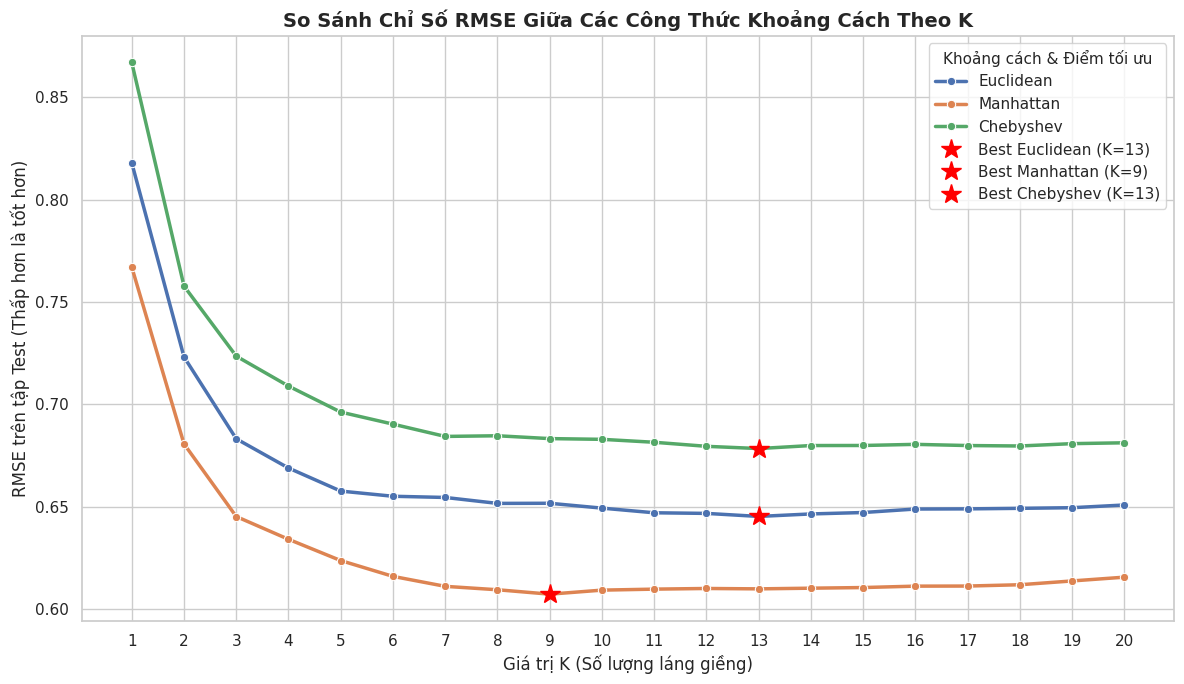

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error

# 1. Định nghĩa dải giá trị K và các metric cần vẽ biểu đồ
k_range = range(1, 21)
metrics_to_plot = {
    'Euclidean': {'metric': 'euclidean'},
    'Manhattan': {'metric': 'manhattan'},
    'Chebyshev': {'metric': 'chebyshev'}
}

plot_data = []

# 2. Chạy thử nghiệm để thu thập dữ liệu RMSE
for name, params in metrics_to_plot.items():
    for k in k_range:
        knn = KNeighborsRegressor(n_neighbors=k, **params)
        knn.fit(X_train_scaled, y_train)
        y_pred = knn.predict(X_test_scaled)
        rmse = np.sqrt(mean_squared_error(y_test, y_pred))

        plot_data.append({
            'K': k,
            'Metric': name,
            'RMSE': rmse
        })

df_plot = pd.DataFrame(plot_data)

# 3. Vẽ biểu đồ so sánh trực quan
plt.figure(figsize=(12, 7))
sns.set_theme(style="whitegrid")

# Vẽ đường xu hướng RMSE của từng công thức
sns.lineplot(data=df_plot, x='K', y='RMSE', hue='Metric', marker='o', linewidth=2.5)

# Tìm và đánh dấu điểm tối ưu của từng công thức lên biểu đồ
colors = {'Euclidean': 'blue', 'Manhattan': 'orange', 'Chebyshev': 'green'}
for name in metrics_to_plot.keys():
    sub_df = df_plot[df_plot['Metric'] == name]
    best_row = sub_df.loc[sub_df['RMSE'].idxmin()]
    plt.plot(best_row['K'], best_row['RMSE'], marker='*', markersize=15,
             color='red', linestyle='None', label=f"Best {name} (K={int(best_row['K'])})")

plt.title("So Sánh Chỉ Số RMSE Giữa Các Công Thức Khoảng Cách Theo K", fontsize=14, fontweight='bold')
plt.xlabel("Giá trị K (Số lượng láng giềng)", fontsize=12)
plt.ylabel("RMSE trên tập Test (Thấp hơn là tốt hơn)", fontsize=12)
plt.xticks(k_range)
plt.legend(title="Khoảng cách & Điểm tối ưu", title_fontsize='11', loc='upper right')
plt.tight_layout()
plt.show()

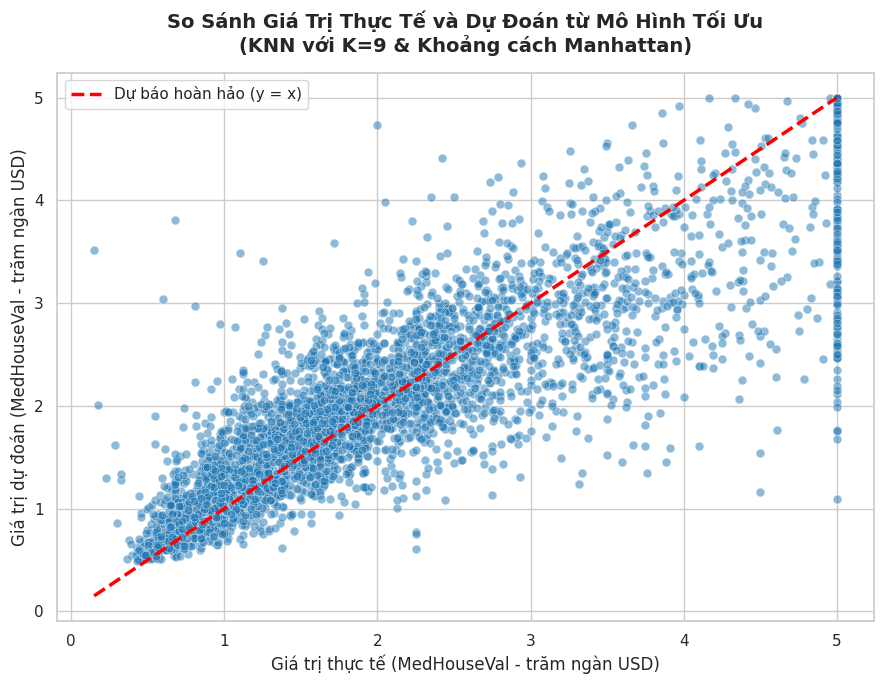

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Sử dụng mô hình tốt nhất từ Grid Search để dự đoán (đã lưu trong biến y_test_pred)
# Ở đây chúng ta sẽ trực quan hóa kết quả này

plt.figure(figsize=(9, 7))
sns.set_theme(style="whitegrid")

# Vẽ biểu đồ phân tán giữa giá trị thực tế và dự đoán
sns.scatterplot(x=y_test, y=y_test_pred, alpha=0.5, color='#1f77b4', edgecolor='w', s=40)

# Đường chéo nét đứt đại diện cho dự báo hoàn hảo (y = x)
min_val = min(y_test.min(), y_test_pred.min())
max_val = max(y_test.max(), y_test_pred.max())
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2.5, label='Dự báo hoàn hảo (y = x)')

# Thiết lập tiêu đề và nhãn
plt.title("So Sánh Giá Trị Thực Tế và Dự Đoán từ Mô Hình Tối Ưu\n(KNN với K=9 & Khoảng cách Manhattan)", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Giá trị thực tế (MedHouseVal - trăm ngàn USD)", fontsize=12)
plt.ylabel("Giá trị dự đoán (MedHouseVal - trăm ngàn USD)", fontsize=12)

plt.legend(loc='upper left', fontsize=11)
plt.tight_layout()
plt.show()
